In [1]:
import numpy as np
import pandas as pd 
from sklearn.model_selection import *
from sklearn.preprocessing import *
from sklearn.metrics import *
from lightgbm import LGBMClassifier
import gc

from tqdm import tqdm, tqdm_notebook

import warnings
warnings.simplefilter('ignore')


from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

import datetime
import time

In [3]:
train = pd.read_csv('Train.csv')
test = pd.read_csv('Test.csv')
ss = pd.read_csv('SampleSubmission.csv')

In [4]:
prod_cols = ['P5DA', 'RIBP', '8NN1','7POT', '66FJ', 'GYSR', 'SOP4', 'RVSZ', 'PYUQ', 'LJR9', 'N2MW', 'AHXO',
             'BSTQ', 'FM3X', 'K6QO', 'QBOL', 'JWFN', 'JZ9D', 'J9JW', 'GHYX', 'ECY3']

In [5]:
miss_prod_lst = []
for p in prod_cols:
    tmp_df = train[train[p] == 1]
    tmp_df['target'] = p
    tmp_df[p] = 0  
    miss_prod_lst.append(tmp_df)
train = pd.concat(miss_prod_lst, axis=0)

In [6]:
train = train.sample(frac=1, random_state=2)
mapper = pd.Series(index = train['target'].unique(), data = np.arange(train['target'].nunique())).to_dict()
rev_mapper = {val: key for key, val in mapper.items()}
train['target'] = train['target'].map(mapper)

In [7]:
train.nunique()

ID                          29132
join_date                     132
sex                             2
marital_status                  8
birth_year                     61
branch_code                    15
occupation_code               233
occupation_category_code        6
P5DA                            2
RIBP                            2
8NN1                            2
7POT                            2
66FJ                            2
GYSR                            2
SOP4                            2
RVSZ                            2
PYUQ                            2
LJR9                            2
N2MW                            2
AHXO                            2
BSTQ                            2
FM3X                            2
K6QO                            2
QBOL                            2
JWFN                            2
JZ9D                            2
J9JW                            2
GHYX                            2
ECY3                            2
target        

In [8]:
df = pd.concat([train, test]).reset_index(drop = True)
D_COL = 'join_date'
df[D_COL] = pd.to_datetime(df[D_COL], format = '%d/%m/%Y')
for f in ['month', 'year', 'week']:
    df[f] = getattr(df[D_COL].dt, f)
cat_cols = ['marital_status', 'branch_code', 'occupation_code', 'occupation_category_code', 'sex']
df[cat_cols] = df[cat_cols].apply(lambda x: pd.factorize(x)[0])
df['total_products_recommended'] = df[prod_cols].sum(axis = 1) # + 1
df['day_since_start'] = (df[D_COL] - df[D_COL].min()).dt.days

prod_cols_freq_sorted = df['target'].map(rev_mapper).value_counts().index.tolist()
prod_df = df[prod_cols].copy().astype('str')

In [9]:
for p in tqdm_notebook(prod_cols_freq_sorted):
    df[f'branch_code_{p}_sum'] = df['branch_code'].map(df.groupby('branch_code')[p].sum())

In [10]:
df['branch_occupation_nunique'] = df['branch_code'].map(df.groupby('branch_code')['occupation_code'].nunique())
df['occupation_branch_nunique'] = df['occupation_code'].map(df.groupby('occupation_code')['branch_code'].nunique())

In [11]:
from itertools import combinations


cc = list(combinations(prod_cols,2))
tmp = pd.concat([df[c[1]].sub(df[c[0]]) for c in cc], axis=1, keys=cc)
tmp.columns = tmp.columns.map(''.join)
print (tmp.shape)
df = pd.concat([df, tmp], axis=1)

(76353, 210)


In [12]:
df.loc[~df['marital_status'].isin([0,1,2]), 'marital_status'] = np.nan


In [13]:
df['prod_comb'] = ''
for p in tqdm_notebook(prod_cols_freq_sorted):
    df['prod_comb'] = df['prod_comb'] + df[p].astype('str')
df['prod_comb'] = pd.factorize(df['prod_comb'])[0]

In [14]:
def nth_most_freq(x, n):
    try:
        return x.value_counts().index.values[n-1]
    except:
        return np.nan
    
def nth_most_freq_cnt(x, n):
    try:
        return x.value_counts().values[n-1]
    except:
        return np.nan

In [15]:
df['prod_comb_freq'] = df['prod_comb'].map(df['prod_comb'].value_counts(normalize=True))

In [16]:
vc = df['prod_comb'].value_counts()
less_freq_prod_comb = vc[vc < 5].index.tolist()
df.loc[df['prod_comb'].isin(less_freq_prod_comb), 'prod_comb'] = np.nan
df = pd.get_dummies(df, columns = ['occupation_code', 'occupation_category_code', 'branch_code', 'prod_comb'])
train, test = df[:train.shape[0]].reset_index(drop = True), df[train.shape[0]:].reset_index(drop = True)
train.shape, test.shape

((66353, 804), (10000, 804))

In [17]:
tmp = train[train['target'] == 20]
train = pd.concat([train, tmp], axis=0)

In [18]:
train = train[train['total_products_recommended'] <= 7]

In [19]:
ID_COL, TARGET_COL = 'ID', 'target'
features = [c for c in train.columns if c not in [ID_COL, TARGET_COL, 'join_date']]
trn, val = train_test_split(train, test_size = 0.2, stratify=train[TARGET_COL], random_state=2)

target = train[TARGET_COL]
len(features)

801

In [20]:
f2 = prod_cols

f3 = [c for c in features if 'branch_code' in c and 'sum' in c]
f4 = [c for c in features if 'occupation_code' in c]

f5 = [c for c in features if 'prod_comb' in c]
f6 = [c for c in features if 'branch_code' in c and c not in f3]
f7 = [c for c in features if c not in f2 + f3 + f4 + f5 + f6]

In [21]:
def partial_feature_score(feats):
    
    max_iter = 5
    folds = GroupKFold(n_splits = max_iter)
    oofs = np.zeros((len(train), 21))
    preds_test = np.zeros((len(test), 21))
    
    features = feats

    for fold_, (trn_idx, val_idx) in enumerate(folds.split(train, target.values, train[ID_COL])):

        print(f'\n---- Fold {fold_} -----\n')

        X_trn, y_trn = train.iloc[trn_idx][features], target.iloc[trn_idx]
        X_val, y_val = train.iloc[val_idx][features], target.iloc[val_idx]
        X_test = test[features]


        clf = LGBMClassifier( n_estimators = 700, learning_rate = 0.07, num_leaves=50, max_depth=6, reg_alpha=2)
        _ = clf.fit(X_trn, y_trn, eval_set = [(X_trn, y_trn), (X_val, y_val)], verbose = 100, early_stopping_rounds = 100)

        oofs[val_idx] = clf.predict_proba(X_val)
        preds_test += clf.predict_proba(X_test)/max_iter

    
    print(f'\nOOF val score: {log_loss(target, oofs)}')
    return oofs.max(axis = 1), preds_test.max(axis=1)

    

In [22]:
par_train = pd.DataFrame()
par_test = pd.DataFrame()
for i, feats in enumerate([f2, f3, f4, f5, f6, f7]):
    
    oof, pred = partial_feature_score(feats)
    par_train[i] = oof
    par_test[i] = pred
    
    print("\n")


---- Fold 0 -----

Training until validation scores don't improve for 100 rounds
[100]	training's multi_logloss: 0.621277	valid_1's multi_logloss: 0.640781
[200]	training's multi_logloss: 0.612564	valid_1's multi_logloss: 0.633186
[300]	training's multi_logloss: 0.612081	valid_1's multi_logloss: 0.63298
[400]	training's multi_logloss: 0.612008	valid_1's multi_logloss: 0.632979
Early stopping, best iteration is:
[308]	training's multi_logloss: 0.612076	valid_1's multi_logloss: 0.632978

---- Fold 1 -----

Training until validation scores don't improve for 100 rounds
[100]	training's multi_logloss: 0.623412	valid_1's multi_logloss: 0.627301
[200]	training's multi_logloss: 0.615005	valid_1's multi_logloss: 0.619428
[300]	training's multi_logloss: 0.614586	valid_1's multi_logloss: 0.61921
[400]	training's multi_logloss: 0.61455	valid_1's multi_logloss: 0.6192
Early stopping, best iteration is:
[370]	training's multi_logloss: 0.614554	valid_1's multi_logloss: 0.619198

---- Fold 2 -----

T

In [23]:
train = pd.concat([train.reset_index(drop = True), par_train.reset_index(drop = True)], axis=1)
test = pd.concat([test.reset_index(drop = True), par_test.reset_index(drop = True)], axis=1)

In [24]:
features = [c for c in train.columns if c not in [ID_COL, TARGET_COL, 'join_date']]

In [25]:
training_start_time = time.time()

max_iter = 5
folds = StratifiedKFold(n_splits = max_iter)
folds = GroupKFold(n_splits = max_iter)
oofs = np.zeros((len(train), 21))
preds_test = np.zeros((len(test), 21))

feature_importance_df = pd.DataFrame()

for fold_, (trn_idx, val_idx) in enumerate(folds.split(train, target.values, train[ID_COL])):
#     if fold_ == 0:
#         continue
    
    print(f'\n---- Fold {fold_} -----\n')
    
    fold_start_time = time.time()
    
    X_trn, y_trn = train.iloc[trn_idx][features], target.iloc[trn_idx]
    X_val, y_val = train.iloc[val_idx][features], target.iloc[val_idx]
    X_test = test[features]
    
    
    clf = LGBMClassifier( n_estimators = 10000, learning_rate = 0.05, num_leaves=50, max_depth=12, colsample_bytree = 0.5, reg_alpha=2, reg_lambda=3)
    _ = clf.fit(X_trn, y_trn, eval_set = [(X_trn, y_trn), (X_val, y_val)], verbose = 100, early_stopping_rounds = 100)
    
    oofs[val_idx] = clf.predict_proba(X_val)
    current_test_pred = clf.predict_proba(X_test)
    print(current_test_pred.shape)
    preds_test += clf.predict_proba(X_test)/max_iter

    fold_importance_df = pd.DataFrame({'feature': X_trn.columns.tolist(), 'importance': clf.feature_importances_})
    feature_importance_df = pd.concat([feature_importance_df, fold_importance_df], axis=0)
    
    fold_end_time = time.time()
    total_fold_time = int(fold_end_time - fold_start_time)
    
    print(f"\n->-> Fold ran for {(total_fold_time)//60} minutes {(total_fold_time)%60} seconds")
    

print(f'\nOOF val score: {log_loss(target, oofs)}')
training_end_time = time.time()
total_training_time = int(training_end_time - training_start_time)

print(f'\n->-> Total training time: {(total_training_time)//60} minutes {(total_training_time)%60} seconds')



---- Fold 0 -----

Training until validation scores don't improve for 100 rounds
[100]	training's multi_logloss: 0.311778	valid_1's multi_logloss: 0.402135
[200]	training's multi_logloss: 0.240207	valid_1's multi_logloss: 0.383206
[300]	training's multi_logloss: 0.204251	valid_1's multi_logloss: 0.38392
Early stopping, best iteration is:
[227]	training's multi_logloss: 0.228822	valid_1's multi_logloss: 0.382778
(10000, 21)

->-> Fold ran for 2 minutes 4 seconds

---- Fold 1 -----

Training until validation scores don't improve for 100 rounds
[100]	training's multi_logloss: 0.313595	valid_1's multi_logloss: 0.397831
[200]	training's multi_logloss: 0.241336	valid_1's multi_logloss: 0.378789
[300]	training's multi_logloss: 0.205078	valid_1's multi_logloss: 0.380448
Early stopping, best iteration is:
[219]	training's multi_logloss: 0.233024	valid_1's multi_logloss: 0.378693
(10000, 21)

->-> Fold ran for 1 minutes 59 seconds

---- Fold 2 -----

Training until validation scores don't impro

In [26]:
print(f'\nOOF val score: {log_loss(target, oofs)}')


OOF val score: 0.3798626799539924


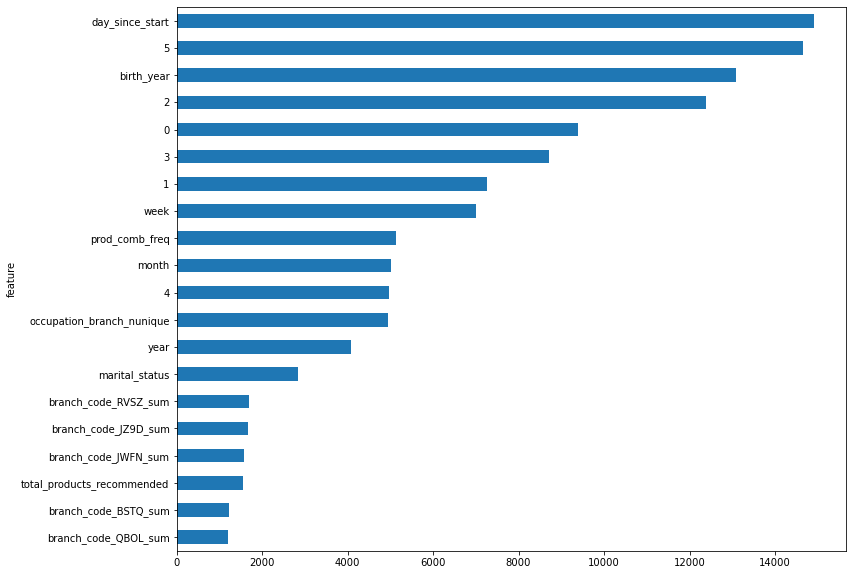

In [27]:
fi = feature_importance_df.groupby('feature')['importance'].mean()
fi.sort_values(ascending=False)[:20][::-1].plot(kind = 'barh', figsize=(12, 10))

In [28]:
oofs_df = pd.DataFrame(oofs).rename(rev_mapper, axis=1)
oofs_df['ID'] = train['ID'].values
oofs_df_melted = pd.melt(oofs_df, id_vars = 'ID', value_vars = prod_cols, var_name='prod', value_name = 'target')

In [29]:
train_cpy = train[['ID', 'target']]
train_cpy['target'] = train_cpy['target'].map(rev_mapper)
train_cpy = pd.get_dummies(train_cpy, columns = ['target'], prefix='', prefix_sep='')
train_cpy = train_cpy[oofs_df.columns.tolist()]
train_cpy_melted = pd.melt(train_cpy, id_vars = 'ID', value_vars = prod_cols, var_name='prod', value_name = 'target')
oofs_df_melted.loc[train_cpy_melted['target'] == 1, 'target'] = 1
log_loss(train_cpy_melted['target'], oofs_df_melted['target'])

0.01145361591213173

In [30]:
test_preds_df = pd.DataFrame(preds_test).rename(rev_mapper, axis=1)
test_preds_df['ID'] = test['ID'].values
test_preds_melted = pd.melt(test_preds_df, id_vars = 'ID', value_vars = prod_cols, var_name='prod', value_name = 'target')

In [31]:
test_preds_melted['ID X PCODE'] = test_preds_melted['ID'].astype('str') + ' X ' + test_preds_melted['prod']
mapper = pd.Series(index = test_preds_melted['ID X PCODE'], data = test_preds_melted['target'].values)

In [32]:
fltr = ss['Label'] != 1
ss.loc[fltr, 'Label'] = ss.loc[fltr, 'ID X PCODE'].map(mapper)
ss['Label'].describe().round(4)
ss.to_csv('m10_v4.csv', index=False)

count    210000.0000
mean          0.1088
std           0.2990
min           0.0000
25%           0.0000
50%           0.0001
75%           0.0019
max           1.0000
Name: Label, dtype: float64

In [33]:
ss.head(10)

,ID X PCODE,Label
0,F86J5PC X P5DA,0.000026
1,F86J5PC X RIBP,0.000313
2,F86J5PC X 8NN1,0.000035
3,F86J5PC X 7POT,0.000131
4,F86J5PC X 66FJ,0.000082
5,F86J5PC X GYSR,0.000019
6,F86J5PC X SOP4,0.000163
7,F86J5PC X RVSZ,1.000000
8,F86J5PC X PYUQ,0.000967
9,F86J5PC X LJR9,0.000093
